In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [3]:
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

In [4]:
real_text = real["text"].head(2000).fillna("")
fake_text = fake["text"].head(2000).fillna("")

In [5]:
# convert text into word counts
vectorizer = CountVectorizer(stop_words="english", max_features=3000, min_df=2, max_df=0.95)

all_text = pd.concat([real_text, fake_text], ignore_index=True)
all_matrix = vectorizer.fit_transform(all_text)

real_matrix = all_matrix[:len(real_text)]
fake_matrix = all_matrix[:len(real_text):]

In [6]:
# LDA topic modelling
lda = LatentDirichletAllocation(n_components=5, random_state = 42, max_iter=10)
lda.fit(all_matrix)

real_topics = lda.transform(real_matrix)
fake_topics = lda.transform(fake_matrix)

In [7]:
words = vectorizer.get_feature_names_out()

print("MAIN TOPICS AND KEYWORDS")

print("Topic 1:", ", ".join(words[lda.components_[0].argsort()[-10:][::-1]]))
print("Topic 2:", ", ".join(words[lda.components_[1].argsort()[-10:][::-1]]))
print("Topic 3:", ", ".join(words[lda.components_[2].argsort()[-10:][::-1]]))
print("Topic 4:", ", ".join(words[lda.components_[3].argsort()[-10:][::-1]]))
print("Topic 5:", ", ".join(words[lda.components_[4].argsort()[-10:][::-1]]))

MAIN TOPICS AND KEYWORDS
Topic 1: said, trump, president, reuters, united, states, washington, north, department, korea
Topic 2: trump, president, russia, house, donald, white, said, campaign, investigation, comey
Topic 3: said, trump, republican, president, house, senate, court, democratic, moore, state
Topic 4: trump, people, twitter, just, donald, like, image, president, com, featured
Topic 5: tax, said, percent, senate, republicans, house, republican, trump, legislation, obamacare


In [11]:
# compare topic distribution
real_dist = real_topics.mean(axis=0)
fake_dist = fake_topics.mean(axis=0)

result = pd.DataFrame({
    "Topic": ["Topic 1", "Topic 2", "Topic 3", "Topic 4", "Topic 5"],
    "Real News": real_dist,
    "Fake News": fake_dist
})

print(result.round(3))

     Topic  Real News  Fake News
0  Topic 1      0.359      0.359
1  Topic 2      0.094      0.094
2  Topic 3      0.248      0.248
3  Topic 4      0.049      0.049
4  Topic 5      0.250      0.250


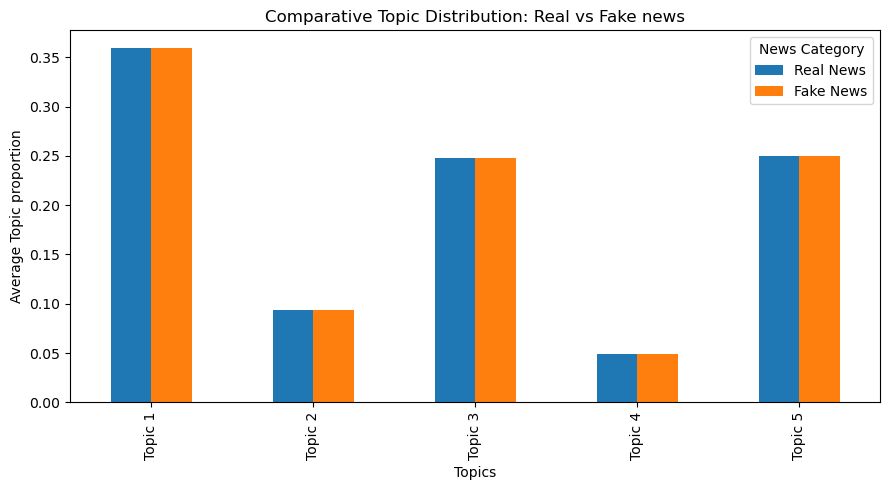

In [13]:
result.plot(x="Topic", y=["Real News", "Fake News"], kind="bar", figsize=(9,5))
plt.title("Comparative Topic Distribution: Real vs Fake news")
plt.xlabel("Topics")
plt.ylabel("Average Topic proportion")
plt.legend(title="News Category")
plt.tight_layout()
plt.show()